# Connections · Statistical learning and puzzle solving

**BERN02 | Reproducible data science**

This notebook answers two related questions:

1. What features describe the structure and difficulty of a Connections puzzle?
2. Can we recover the four correct groups of four words from an unseen puzzle?

The explanations and figures live here; reusable Python code lives in the
`connections/` package. Run cells in order from the project root.

## 1 · Setup and data provenance

Choose how to prepare local data **before** running the analysis. The default
uses existing local CSVs and makes no network requests.

- `"existing"`: use CSVs already in `data/`.
- `"database"`: rebuild the word CSV from `data/raw/connections.db`.
- `"scrape"`: collect missing puzzles from the source website, update the SQLite
  database, and rebuild the word CSV.

Set `REBUILD_SEMANTIC = True` to generate semantic group/pair CSVs using
Sentence Transformers (downloads a pretrained model on first use). A new clone
without datasets needs `DATA_MODE = "scrape"` and `REBUILD_SEMANTIC = True`.
This can take time and requires internet access. Scraped data may differ from
previously published analysis because the source changes over time.

**Licensing:** Raw databases and CSVs stay local and are ignored by Git;
notebook analysis outputs can be committed. See `DATA_NOTICE.md`.

In [1]:
# Change these settings before running the notebook.
DATA_MODE = "existing"       # "existing", "database", or "scrape"
REBUILD_SEMANTIC = False    # True requires sentence-transformers
START_DATE = None          # e.g. "2023-06-12"; None starts at puzzle #1
END_DATE = None            # e.g. "2026-10-12"; None ends yesterday

from connections.pipeline import prepare_data
prepare_data(
    mode=DATA_MODE,
    semantic=REBUILD_SEMANTIC,
    start_date=START_DATE,
    end_date=END_DATE,
)

Data ready (existing mode).


In [2]:
import matplotlib.pyplot as plt
from IPython.display import display
from connections.data import (load_data, quality_report, puzzle_features,
                              written_word_puzzles, puzzle_examples)
from connections.analysis import (difficulty_trends, color_summary,
    difficulty_correlations, difficulty_regression, puzzle_structure, vocabulary_tables)

words, groups, pairs = load_data()
print(f"{len(words):,} word rows across {words.puzzle_date.nunique():,} puzzles")

19,504 word rows across 1,219 puzzles


## 2 · Data quality

A standard puzzle has 16 words in four categories. Difficulty is not available
for every date. We retain missing ratings in the source data rather than
silently inventing values.

In [3]:
quality = quality_report(words)
display(quality.head())
print("Nonstandard puzzle shapes:", (~quality.valid_shape).sum())
print("Missing difficulty ratings:", quality.difficulty.isna().sum())

,puzzle_date,word_rows,unique_words,groups,difficulty,valid_shape
0,2023-06-12,16,16,4,NaN,True
1,2023-06-13,16,16,4,NaN,True
2,2023-06-14,16,16,4,NaN,True
3,2023-06-15,16,16,4,NaN,True
4,2023-06-16,16,16,4,NaN,True


Nonstandard puzzle shapes: 0
Missing difficulty ratings: 346


## 3 · Difficulty over time and semantic similarity

Difficulty is a published score, not a directly observed player-success rate.
Similarity values come from the bundled semantic-statistics CSVs.

,year,count,mean,median
0,2024,223,2.939462,3.0
1,2025,365,2.742740,2.8
2,2026,285,2.262105,2.3


,color,count,mean,std
0,blue,1219,0.293641,0.068861
1,green,1219,0.316568,0.074187
2,purple,1219,0.263698,0.059121
3,yellow,1219,0.331251,0.081190


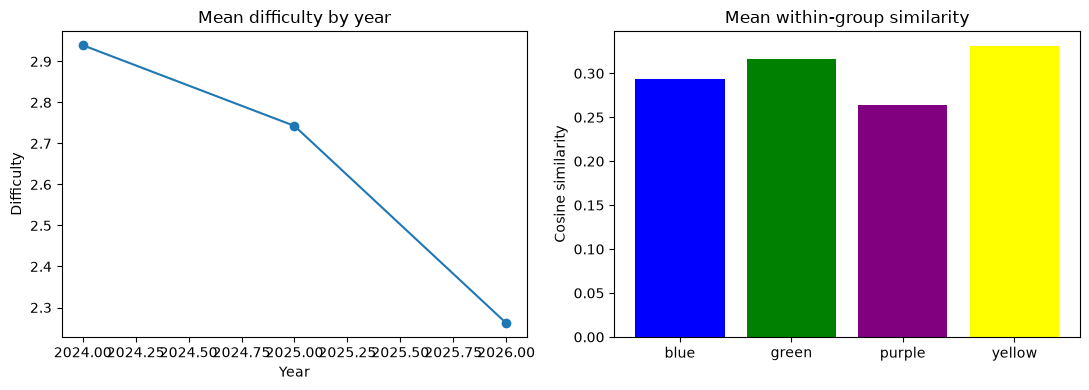

In [4]:
puzzles = puzzle_features(words, pairs)
annual = difficulty_trends(puzzles)
colors = color_summary(groups)
display(annual, colors)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(annual.year, annual["mean"], marker="o")
axes[0].set(title="Mean difficulty by year", xlabel="Year", ylabel="Difficulty")
axes[1].bar(colors.color, colors["mean"], color=colors.color)
axes[1].set(title="Mean within-group similarity", ylabel="Cosine similarity")
plt.tight_layout()
plt.show()

## 4 · Correlations and linear regression

Spearman correlations describe monotonic relationships. Regression is evaluated
on later puzzles, with a training-mean baseline and time-series cross-validation.
The standardization is fitted on training observations only.

In [5]:
clean_puzzles = written_word_puzzles(puzzles)
correlations = difficulty_correlations(clean_puzzles)
comparison, coefficients, cv = difficulty_regression(clean_puzzles)
display(correlations.round(3), comparison.round(3), coefficients.round(3), cv.round(3))

,feature,n,spearman_correlation,p_value
0,within_group_similarity,873,0.013,0.693
1,cross_group_similarity,873,0.129,0.000
2,similarity_gap,873,-0.097,0.004
3,mean_word_length,873,-0.123,0.000
4,sd_word_length,873,-0.094,0.005


,model,test_MAE
0,Training mean,0.619
1,Linear regression,0.592


,feature,coefficient
0,within_group_similarity,-0.014
1,cross_group_similarity,0.042
2,similarity_gap,-0.053
3,mean_word_length,-0.027
4,sd_word_length,-0.012


,fold,test_MAE
0,1,0.442
1,2,0.496
2,3,0.559
3,4,0.687
4,5,0.551


## 5 · PCA and K-means: clusters of *whole puzzles*

Each row represents one complete puzzle, summarized by similarity and word
length. These clusters describe puzzle types; **they do not solve a puzzle**.
The emoji-only April 1, 2024 puzzle is excluded because its word lengths and
embeddings are not comparable to ordinary written words.

,cluster,puzzles,mean_difficulty,mean_within_similarity,mean_cross_similarity
0,0,561,2.638,0.287,0.239
1,1,516,2.694,0.329,0.267
2,2,141,2.511,0.251,0.201


PCA explained variance: [0.676 0.18 ]


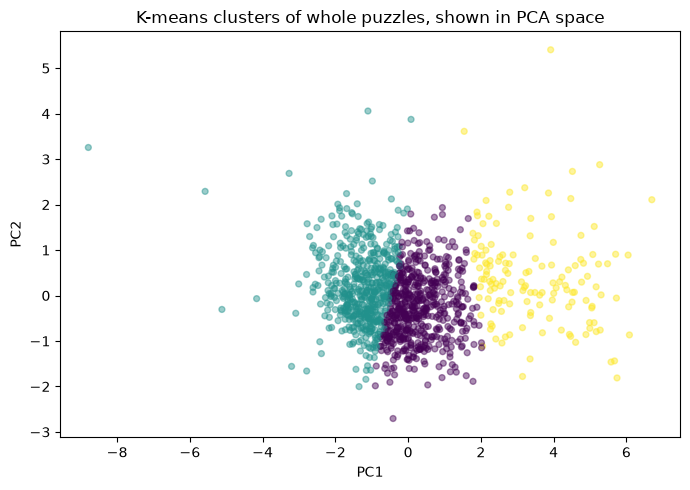

In [6]:
coordinates, cluster_summary, variance = puzzle_structure(clean_puzzles)
display(cluster_summary.round(3))
print("PCA explained variance:", variance.round(3))
plt.figure(figsize=(7, 5))
plt.scatter(coordinates.PC1, coordinates.PC2, c=coordinates.cluster, s=18, alpha=.45)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-means clusters of whole puzzles, shown in PCA space")
plt.tight_layout()
plt.show()

## 6 · Repeated words and categories

These counts describe the dataset; they are not used as test-set labels by the
unsupervised solver.

In [7]:
word_counts, category_counts = vocabulary_tables(words)
display(word_counts.sort_values("appearances", ascending=False).head(10))
display(category_counts.sort_values("puzzles", ascending=False).head(10))

,word,appearances,puzzles_used
464,BALL,30,30
6421,RING,25,25
2927,FLY,22,22
504,BAR,22,22
1348,CHECK,21,21
4340,LEAD,20,20
759,BLUE,19,19
4009,JACK,19,19
8642,WING,19,19
7409,STICK,18,18


,category,puzzles
136,ANAGRAMS,10
1604,HOMOPHONES,10
1340,FISH,8
2391,PALINDROMES,6
3481,THINGS THAT ARE RED,6
2031,MAGAZINES,6
2203,MUSICAL INSTRUMENTS,5
1027,EAT VORACIOUSLY,5
2195,MUSIC GENRES,5
2460,PASTA SHAPES,4


## 7 · Supervised solution prediction

The classifier sees 120 word pairs per puzzle and estimates whether each pair
belongs to the same answer group. We compare **logistic regression** with
**random forest**. The final grouping algorithm assigns each word to exactly
one group of four.

The chronological split is 60% training, 20% validation and 20% testing.
The model is selected using validation ROC AUC; test results are reported only
after selection. Lexical features are an intentionally simple baseline.

In [8]:
from connections.supervised import compare_classifiers, solve_with_classifier
examples = puzzle_examples(words)
lexical_models, lexical_results, lexical_winner = compare_classifiers(examples)
display(lexical_models.round(3))
print("Mean correctly recovered groups:", round(lexical_results.correct_groups.mean(), 3))
print("Fully solved:", f"{lexical_results.fully_solved.mean():.1%}")

,model,validation_AUC,test_AUC
0,Logistic regression,0.535,0.551
1,Random forest,0.531,0.532


Mean correctly recovered groups: 0.025
Fully solved: 0.0%


## 8 · Optional: semantic features with Sentence Transformers

A fixed pretrained `all-MiniLM-L6-v2` encoder represents meaning more directly
than spelling features. Its vectors are **inputs** to course-level classifiers,
not a neural network trained in this project.

Install `pip install -r requirements-semantic.txt` before running the next cell.
The first run may download the pretrained model. If you are working offline,
skip this cell and continue with the lexical baseline.

In [9]:
from connections.clustering import load_encoder

# Compare semantic + lexical pair features on unseen puzzles.
# This can take several minutes and requires the pretrained model.
encoder = load_encoder()
semantic_models, semantic_results, semantic_winner = compare_classifiers(examples, encoder)
display(semantic_models.round(3))
display(semantic_results.head())

/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 823.57it/s]


,model,validation_AUC,test_AUC
0,Logistic regression,0.656,0.651
1,Random forest,0.637,0.631


,puzzle_date,correct_groups,fully_solved
0,2026-02-11,0,0
1,2026-02-12,0,0
2,2026-02-13,0,0
3,2026-02-14,0,0
4,2026-02-15,0,0


## 9 · Unsupervised solver: balanced K-means on 16 words

This is a **different** clustering task from Section 5. Sentence Transformers
creates one vector per word. Balanced K-means uses four centers and constrained
assignment so each group contains exactly four words. It needs no historical
solutions to predict a new puzzle.

The next cell is opt-in because the pretrained model may need downloading.
To evaluate the most recent 30 puzzles from a terminal, run
`python -m connections.clustering --evaluate 30`.

In [10]:
from connections.clustering import solve_puzzle, evaluate_puzzles

sample_words = [
    "APPLE", "DOG", "RED", "PIANO",
    "BANANA", "CAT", "BLUE", "GUITAR",
    "ORANGE", "HORSE", "GREEN", "VIOLIN",
    "GRAPE", "COW", "YELLOW", "DRUM",
]

# Predict a new puzzle or evaluate historical puzzles.
encoder = load_encoder()
predicted_groups = solve_puzzle(sample_words, encoder)
for number, group in enumerate(predicted_groups, 1):
    print(f"Group {number}: {', '.join(group)}")
clustering_results = evaluate_puzzles(encoder, n_test=30)
display(clustering_results.head())

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3476.94it/s]


Group 1: DOG, CAT, HORSE, COW
Group 2: RED, BLUE, GREEN, YELLOW
Group 3: APPLE, BANANA, ORANGE, GRAPE
Group 4: PIANO, GUITAR, VIOLIN, DRUM
Puzzles evaluated: 30
Mean correct groups: 0.433 / 4
Fully solved: 0.0%


,puzzle_date,correct_groups,fully_solved
0,2026-09-13,0,0
1,2026-09-14,0,0
2,2026-09-15,0,0
3,2026-09-16,0,0
4,2026-09-17,0,0


## 11 · Interpretation and limitations

- Puzzle-level PCA/K-means describes **whole puzzles**, while balanced K-means
  attempts to **solve one puzzle** by clustering its words.
- A strong pairwise ROC AUC does not guarantee complete recovery of four groups.
- Semantic similarity can help with related meanings, but Connections also
  depends on homophones, wordplay, ambiguity and intentionally misleading links.
- Difficulty scores are missing for some dates, and the emoji-only puzzle
  needs separate treatment for word-based features.
- Report the **actual** validation/test outputs from your run rather than
  assuming that semantic embeddings necessarily improve performance.



## 10 · Optional neural network: lexical + semantic features

This extension trains a **small multilayer perceptron (MLP)** on both spelling features and fixed Sentence Transformer embeddings. It offers two tasks:

- **Solve puzzles:** classify the 120 word pairs, then assemble four non-overlapping groups of four.
- **Predict difficulty:** summarize the 16 words using lexical and semantic features, without looking at the correct groups. Compare its mean absolute error (MAE) against predicting the training-set mean.

Puzzles are split **chronologically (60% train, 20% validation, 20% test)** before fitting either model. The pretrained encoder is used only for features; it is **not fine-tuned**. The MLP is an optional extension beyond the core BERN02 analysis.

**Note:** First run `pip install -r requirements-semantic.txt`. The first run downloads the embedding model. The MLP experiments may take a few minutes.

In [11]:
# Set to True to train the optional MLPs (requires Sentence Transformers).
RUN_MLP = True

if RUN_MLP:
    from connections.mlp import (
        fit_pair_mlp, fit_difficulty_mlp,
        solve_with_mlp, predict_difficulty,
    )
    from connections.clustering import load_encoder

    encoder = load_encoder()
    pair_mlp, pair_metrics, group_results = fit_pair_mlp(examples, encoder)
    difficulty_mlp, difficulty_metrics = fit_difficulty_mlp(examples, encoder)

    display(pair_metrics.round(3), difficulty_metrics.round(3))
    print("Average correct groups:", round(group_results.correct_groups.mean(), 3))
    print("Complete puzzles solved:", int(group_results.fully_solved.sum()))

    # Use the same models on any new set of 16 words.
    predicted_groups = solve_with_mlp(sample_words, pair_mlp, encoder)
    predicted_rating = predict_difficulty(sample_words, difficulty_mlp, encoder)


Batches: 100%|██████████| 69/69 [01:30<00:00,  1.31s/it]


,model,validation_AUC,test_AUC,training_puzzles,validation_puzzles,test_puzzles
0,MLP (lexical + semantic),0.657,0.651,730,244,244


,model,validation_MAE,test_MAE,train_rated,validation_rated,test_rated
0,MLP (lexical + semantic),0.638,0.881,385,244,244
1,Training-mean baseline,0.597,0.781,385,244,244


Average correct groups: 0.025
Complete puzzles solved: 0


In [14]:
import numpy as np
print(np.array(predicted_groups), predicted_rating)

[['APPLE' 'BANANA' 'ORANGE' 'GRAPE']
 ['DOG' 'CAT' 'HORSE' 'COW']
 ['RED' 'BLUE' 'GREEN' 'YELLOW']
 ['PIANO' 'GUITAR' 'VIOLIN' 'DRUM']] 3.4862771961333596


### Interpretation

The word-pair model and difficulty model answer different questions and are evaluated separately. Strong pairwise AUC does not necessarily imply that complete puzzles can be solved. Difficulty prediction is evaluated against a simple baseline; a lower MAE is better. Results are written to `data/derived/` and are **not included as raw datasets in the GitHub repository**.

The lexical and semantic feature functions, chronological split, model fitting, and evaluation are in `connections/mlp.py` so the notebook stays readable.